1. Import libraries
2. Load credit card dataset
3. Examine rows and columns
4. Examine data types
5. Generate descriptive statistics
6. Check missing values
7. Check duplicate records
8. Investigate unusual categorical values
9. Clean/rename variables
10. Begin EDA

In [10]:
## 1. Import Libraries
#The following libraries are imported to support data manipulation, numerical analysis, and data visualization throughout the project.

# Import pandas for loading, organizing, cleaning, and analyzing the dataset.
import pandas as pd
# Import NumPy for numerical calculations used throughout the analysis.
import numpy as np
# Import Matplotlib for creating graphs and visualizing patterns in the data.
import matplotlib.pyplot as plt

In [11]:
## 2. Load Credit Card Dataset

#The credit card default dataset is loaded into the notebook using pandas.
#The dataset will first be inspected to confirm that the file and column headers were read correctly before performing any cleaning or analysis.

# Import the Colab file utility so the dataset can be uploaded
# from the local computer into the current notebook session.
#File name: default of credit card clients.xls
from google.colab import files
uploaded = files.upload()

#File output: cleaned_credit_card_data.csv

Saving default of credit card clients.xls to default of credit card clients.xls


In [12]:
# Load the Excel dataset into a pandas DataFrame.
# A DataFrame allows us to organize and analyze the customer records
# using rows for observations and columns for variables.

# Load the Excel dataset into a pandas DataFrame.
# header=1 tells pandas to use the second row of the Excel file
# as the column names because the first row contains dataset labels
# rather than the actual variable names.

df = pd.read_excel(
    "default of credit card clients.xls",
    header=1
)

# Display the first five rows to verify that the dataset
# and column names were loaded correctly.
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [13]:
## 3. Examine Rows and Columns

#The dimensions and column names of the dataset are examined to understand the number of customer observations and variables available for analysis.

# Determine the number of customer observations and variables in the dataset.
# Knowing the dataset dimensions helps verify that the data was imported
# correctly before beginning the cleaning and analysis process.

rows, columns = df.shape

print("Number of customer observations:", rows)
print("Number of variables:", columns)

# Display all column names to identify the variables available
# for exploratory analysis and future model development.

print("\nColumn Names:")

for column in df.columns:
    print(column)

Number of customer observations: 30000
Number of variables: 25

Column Names:
ID
LIMIT_BAL
SEX
EDUCATION
MARRIAGE
AGE
PAY_0
PAY_2
PAY_3
PAY_4
PAY_5
PAY_6
BILL_AMT1
BILL_AMT2
BILL_AMT3
BILL_AMT4
BILL_AMT5
BILL_AMT6
PAY_AMT1
PAY_AMT2
PAY_AMT3
PAY_AMT4
PAY_AMT5
PAY_AMT6
default payment next month


In [14]:
## 4. Examine Data Types

#The data type of each variable is examined to verify that the dataset was imported correctly.
#Identifying each variable's data type is important before performing statistical analysis, visualization, and model development.

# Display information about the DataFrame, including the column names,
# number of non-null observations, and data type of each variable.
# This helps identify possible missing values or variables that may
# require conversion before analysis.

# Display each variable and its data type in a clean table.
# This verifies how pandas interpreted each variable after importing
# the dataset.

data_types = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

data_types


,Variable,Data Type
0,ID,int64
1,LIMIT_BAL,int64
2,SEX,int64
3,EDUCATION,int64
4,MARRIAGE,int64
5,AGE,int64
6,PAY_0,int64
7,PAY_2,int64
8,PAY_3,int64
9,PAY_4,int64


Reference:

GeeksforGeeks. (2025). Python | Pandas DataFrame.dtypes. https://www.geeksforgeeks.org/python/python-pandas-dataframe-dtypes/

In [15]:
## 5. Generate Descriptive Statistics

#Descriptive statistics are calculated to summarize the numerical variables in the dataset.
#These statistics provide an initial understanding of the distributions, ranges,
  #and possible unusual values before further data cleaning and exploratory analysis.

# Generate descriptive statistics for all numerical variables.
# This provides the count, mean, standard deviation, minimum,
# quartiles, and maximum values for each variable.

df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [16]:
## 6. Check Missing Values

#Missing values are checked for each variable to determine whether any observations require
#additional cleaning or treatment before analysis and model development.

# Count the number of missing values in each variable.
# Missing data could affect the statistical analysis and model results,
# so each column is checked before continuing with the analysis.

missing_values = df.isnull().sum()

print("Missing Values by Variable:")
print(missing_values)

# Calculate the total number of missing values in the dataset.
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)

Missing Values by Variable:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total Missing Values: 0


Reference:

GeeksforGeeks. (2025). Working with missing data in Pandas. https://www.geeksforgeeks.org/python/working-with-missing-data-in-pandas/

In [17]:
## 7. Check Duplicate Records

#The dataset is checked for duplicate customer records. Duplicate observations
#could unintentionally give certain records additional influence during the statistical analysis and model development.

# Count the number of duplicate rows in the dataset.
# Identifying duplicates helps ensure that each customer record
# is represented appropriately in the analysis.

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

# **Finding:** No duplicate records or duplicate customer IDs were identified in the dataset.
# Therefore, no observations were removed due to duplication.

Number of Duplicate Records: 0


In [18]:
## 8. Investigate Categorical Values

# Select the categorical variables that should be inspected before analysis.
categorical_variables = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

# Create an empty list to store the category counts.
category_tables = []

# Count each unique value within every categorical variable.
# The results are combined into one table to make unusual
# or unexpected category codes easier to identify.
for column in categorical_variables:
    counts = df[column].value_counts().sort_index()

    for value, count in counts.items():
        category_tables.append({
            "Variable": column,
            "Value": value,
            "Count": count
        })

# Convert the stored results into a DataFrame for a cleaner display.
category_summary = pd.DataFrame(category_tables)
# Calculate the percentage of customers represented by each category.
category_summary["Percentage"] = (
    category_summary["Count"] / len(df) * 100
)

# Format the count with commas and the percentage to two decimal places.
category_summary["Count"] = (
    category_summary["Count"]
    .map(lambda value: f"{value:,}")
)
category_summary["Percentage"] = (
    category_summary["Percentage"]
    .map(lambda value: f"{value:.2f}%")
)

# Display the completed categorical summary table.
category_summary

,Variable,Value,Count,Percentage
0,SEX,1,"11,888",39.63%
1,SEX,2,"18,112",60.37%
2,EDUCATION,0,14,0.05%
3,EDUCATION,1,"10,585",35.28%
4,EDUCATION,2,"14,030",46.77%
...,...,...,...,...
72,PAY_6,4,49,0.16%
73,PAY_6,5,13,0.04%
74,PAY_6,6,19,0.06%
75,PAY_6,7,46,0.15%


In [19]:
## 9. Clean and Rename Variables

# Variable names and categorical values are reviewed before analysis.
# The target variable is renamed to improve readability and make it easier to
# reference throughout the exploratory analysis and model development.

# Display the current name of the target variable before renaming it.
print(f"Current Target Variable: {df.columns[-1]}")

# Rename the target variable to make it shorter and easier to
# reference throughout the analysis and model development.
df = df.rename(
    columns={"default payment next month": "DEFAULT"}
)

# Count the number of customers in each default category.
# DEFAULT = 0 represents customers who did not default,
# while DEFAULT = 1 represents customers who defaulted.
default_summary = (
    df["DEFAULT"]
    .value_counts()
    .sort_index()
    .reset_index()
)

default_summary.columns = ["Default Status", "Count"]

# Calculate the percentage of customers in each category.
default_summary["Percentage"] = (
    default_summary["Count"] / len(df) * 100
)

# Format the count with commas and the percentage
# to two decimal places.
default_summary["Count"] = (
    default_summary["Count"]
    .map(lambda value: f"{value:,}")
)
default_summary["Percentage"] = (
    default_summary["Percentage"]
    .map(lambda value: f"{value:.2f}%")
)

# Display the completed default summary table.
default_summary

Current Target Variable: default payment next month


,Default Status,Count,Percentage
0,0,"23,364",77.88%
1,1,"6,636",22.12%


**Finding:** Of the 30,000 customers in the dataset, 23,364 (77.88%) did not default and 6,636 (22.12%) defaulted. This indicates that the target variable is imbalanced, with substantially fewer customers in the default group. Because of this imbalance, model performance should be evaluated using additional metrics such as precision, recall, F1 score, and a confusion matrix rather than relying only on accuracy.

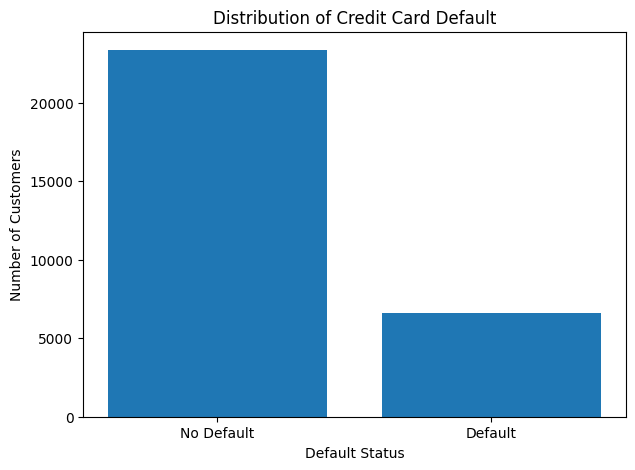

In [20]:
## 10. Exploratory Data Analysis

# Exploratory data analysis is used to examine patterns in the dataset
# and better understand the credit card default variable.

### 10.1 Default Distribution

# Count the number of customers who did and did not default.
default_counts = df["DEFAULT"].value_counts().sort_index()

# Create a bar chart of the default distribution.
plt.figure(figsize=(7, 5))

plt.bar(
    ["No Default", "Default"],
    default_counts
)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")

plt.show()

**Finding:** The majority of customers in the dataset did not default. Of the 30,000 customers, 23,364 (77.88%) did not default, while 6,636 (22.12%) defaulted. This shows that the target variable is imbalanced and should be considered when evaluating the classification model.

In [21]:
## 11. Final Data Validation

#The dataset is checked one final time after the cleaning and preparation process.
#This ensures that the expected number of observations and variables remain and that the
#target variable is correctly formatted before exporting the cleaned dataset.

# Verify the dimensions of the prepared dataset.
# This ensures that observations were not unintentionally removed
# during the data cleaning process.

print("Final Number of Customer Observations:", df.shape[0])
print("Final Number of Variables:", df.shape[1])

# Verify that no missing values were introduced during cleaning.
print("Total Missing Values:", df.isnull().sum().sum())

# Convert the target values to standard Python integers
# so they display cleanly in the notebook output.
target_values = sorted(df["DEFAULT"].unique().tolist())

print("Target Variable Values:", target_values)

Final Number of Customer Observations: 30000
Final Number of Variables: 25
Total Missing Values: 0
Target Variable Values: [0, 1]


Reference:
GeeksforGeeks. (2025, July 28). Count values in Pandas DataFrame.  ⁠GeeksforGeeks

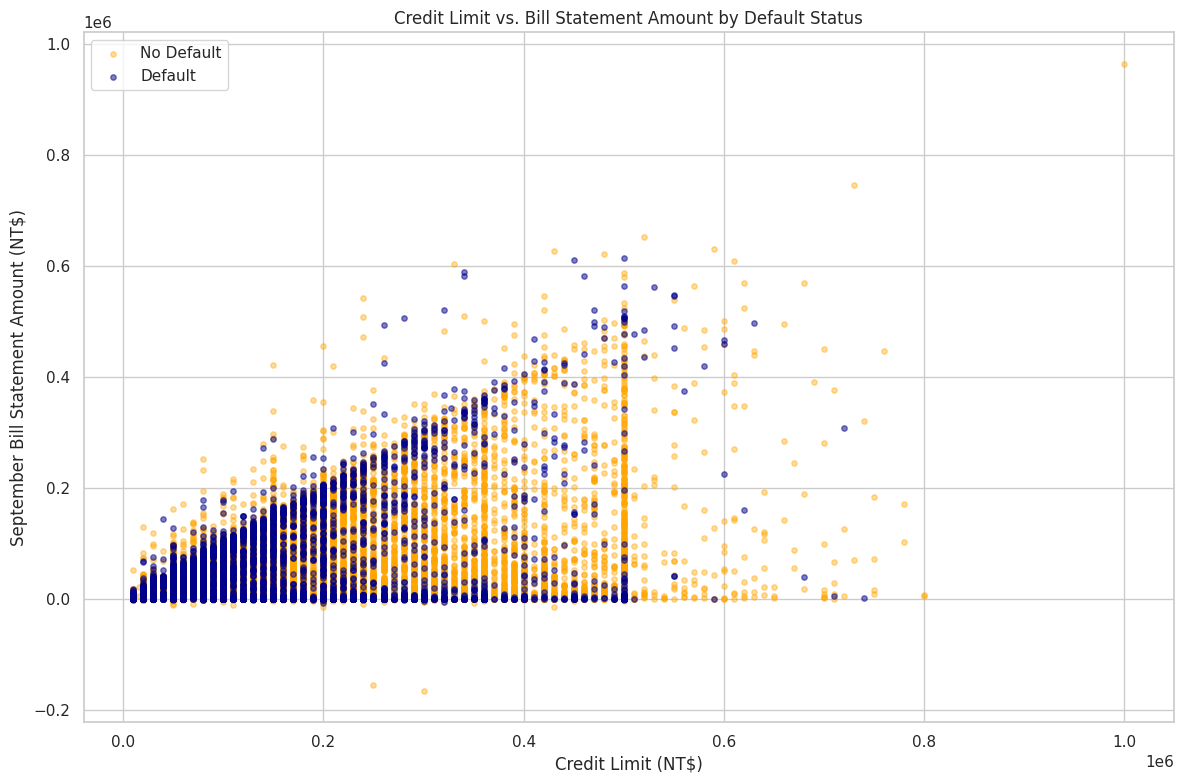

In [42]:
# Scatterplot: Credit Limit vs. Bill Statement Amount
import matplotlib.pyplot as plt

# Independent variable (x)
x = df["LIMIT_BAL"]

# Dependent variable (y)
y = df["BILL_AMT1"]

# Separate customers by default status
no_default = df["DEFAULT"] == 0
default = df["DEFAULT"] == 1

# Scatterplot
plt.figure(figsize=(12, 8))

# Customers who did not default
plt.scatter(
    x[no_default],
    y[no_default],
    color="orange",
    label="No Default",
    alpha=0.4,
    s=15
)

# Customers who defaulted
plt.scatter(
    x[default],
    y[default],
    color="darkblue",
    label="Default",
    alpha=0.5,
    s=15
)

# Display
plt.xlabel("Credit Limit (NT$)")
plt.ylabel("September Bill Statement Amount (NT$)")
plt.title("Credit Limit vs. Bill Statement Amount by Default Status")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Explanation:

The scatter plot compares customers’ credit limits (LIMIT_BAL) with their September 2005 bill statement amounts (BILL_AMT1). Each point represents a customer, with orange representing customers who did not default and dark blue representing customers who defaulted.

The graph shows that customers with higher credit limits generally have a wider range of bill statement amounts. However, both default groups overlap significantly, indicating that credit limits and bill statement amounts alone do not clearly separate customers who defaulted from those who did not. Some observations also contain unusually high or negative bill statement amounts.

These findings suggest that additional variables, such as repayment history, may be useful when predicting credit card default.

In [ ]:
## 12. Export Prepared Dataset

#The prepared dataset is exported as a CSV file so that the same data can be
#used consistently in the Bootstrap and Decision Tree analysis notebooks.

# Create the dataset that will be used for model development.
# The ID variable is removed because it is only a unique customer
# identifier and does not describe a customer's credit behavior.

model_df = df.drop(columns=["ID"])

# Export the prepared dataset as a CSV file.
# index=False prevents pandas from adding an unnecessary index column.

model_df.to_csv(
    "cleaned_credit_card_data.csv",
    index=False
)

# Verify that the modeling dataset was created successfully.
print("Cleaned dataset exported successfully.")
print("Number of Customer Observations:", model_df.shape[0])
print("Number of Modeling Variables:", model_df.shape[1])

# Download the cleaned dataset to the local computer.
from google.colab import files
files.download("cleaned_credit_card_data.csv")

Reference:

GeeksforGeeks. (2024, November 18). Drop columns in DataFrame by label names or by index positions. GeeksforGeeks.  ⁠https://www.geeksforgeeks.org/python/drop-columns-in-dataframe-by-label-names-or-by-index-positions/